In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/abulbasar/data/refs/heads/master/insurance.csv")
df

,age,gender,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [5]:
target = 'charges'
X = df.drop(columns=target) # feature matrix
y = df[target] # outcome variable/label

In [4]:
from sklearn import model_selection, linear_model, preprocessing

In [7]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size = 0.3) # random split
len(X_train)/len(X)

0.6995515695067265

In [21]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size = 0.3) # random split
X_train

,age,gender,bmi,children,smoker,region
80,31,male,26.885,1,no,northeast
975,29,male,22.895,0,yes,northeast
347,46,male,33.345,1,no,northeast
594,41,male,40.260,0,no,southeast
50,18,female,35.625,0,no,northeast
...,...,...,...,...,...,...
306,28,female,27.500,2,no,southwest
159,50,female,27.830,3,no,southeast
722,62,male,37.400,0,no,southwest
225,55,male,33.880,3,no,southeast


In [40]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size = 0.3, 
                                                                   random_state = 978) # random split
X_train

,age,gender,bmi,children,smoker,region
44,38,male,37.050,1,no,northeast
290,28,female,33.400,0,no,southwest
227,58,female,41.910,0,no,southeast
89,55,female,26.980,0,no,northwest
259,19,male,31.920,0,yes,northwest
...,...,...,...,...,...,...
980,54,male,25.460,1,no,northeast
542,63,female,36.300,0,no,southeast
788,29,male,22.515,3,no,northeast
1261,28,male,37.100,1,no,southwest


In [41]:
X_train

,age,gender,bmi,children,smoker,region
44,38,male,37.050,1,no,northeast
290,28,female,33.400,0,no,southwest
227,58,female,41.910,0,no,southeast
89,55,female,26.980,0,no,northwest
259,19,male,31.920,0,yes,northwest
...,...,...,...,...,...,...
980,54,male,25.460,1,no,northeast
542,63,female,36.300,0,no,southeast
788,29,male,22.515,3,no,northeast
1261,28,male,37.100,1,no,southwest


In [42]:
df.region.unique()

<StringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str

In [44]:
X.head()

,age,gender,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


In [48]:
pd.get_dummies(X).head(3)

,age,bmi,children,gender_female,gender_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.90,0,True,False,False,True,False,False,False,True
1,18,33.77,1,False,True,True,False,False,False,True,False
2,28,33.00,3,False,True,True,False,False,False,True,False


In [50]:
pd.get_dummies(X, drop_first=True).head(3)

,age,bmi,children,gender_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.90,0,False,True,False,False,True
1,18,33.77,1,True,False,False,True,False
2,28,33.00,3,True,False,False,True,False


In [51]:
target = 'charges'
X = df.drop(columns=target) # feature matrix
y = df[target] # outcome variable/label
X_dummy = pd.get_dummies(X, drop_first=True)
X_train, X_test, y_train, y_test = model_selection.train_test_split(X_dummy, y, test_size = 0.3, 
                                                                   random_state = 978) # random split
X_train

,age,bmi,children,gender_male,smoker_yes,region_northwest,region_southeast,region_southwest
44,38,37.050,1,True,False,False,False,False
290,28,33.400,0,False,False,False,False,True
227,58,41.910,0,False,False,False,True,False
89,55,26.980,0,False,False,True,False,False
259,19,31.920,0,True,True,True,False,False
...,...,...,...,...,...,...,...,...
980,54,25.460,1,True,False,False,False,False
542,63,36.300,0,False,False,False,True,False
788,29,22.515,3,True,False,False,False,False
1261,28,37.100,1,True,False,False,False,True


In [53]:
a = X_train.age
z = (a - a.mean())/a.std() # z score/standardization
z

44     -0.072029
290    -0.781702
227     1.347318
89      1.134416
259    -1.420408
          ...   
980     1.063449
542     1.702155
788    -0.710735
1261   -0.781702
1168   -0.497833
Name: age, Length: 936, dtype: float64

In [62]:
target = 'charges'
X = df.drop(columns=target) # feature matrix
y = df[target] # outcome variable/label
X_dummy = pd.get_dummies(X, drop_first=True)
X_train, X_test, y_train, y_test = model_selection.train_test_split(X_dummy, y, test_size = 0.3, 
                                                                   random_state = 978) # random split
scaler = preprocessing.StandardScaler()
X_train_std = scaler.fit_transform(X_train) # find mean and std for each column
X_test_std = scaler.transform(X_test)

X_train_std[:,0]

array([-7.20673328e-02, -7.82120212e-01,  1.34803842e+00,  1.13502256e+00,
       -1.42116780e+00,  1.20602785e+00,  7.79996122e-01,  1.13502256e+00,
        1.77407015e+00,  6.99432430e-02, -8.53125499e-01, -1.35016251e+00,
       -1.35016251e+00, -1.42116780e+00,  1.41904371e+00,  8.51001410e-01,
        1.06401727e+00,  1.13502256e+00,  5.66980258e-01, -1.42116780e+00,
        6.99432430e-02,  4.95974970e-01,  1.13502256e+00,  4.24969682e-01,
       -9.24130787e-01,  4.95974970e-01,  6.99432430e-02, -5.69104348e-01,
        1.06401727e+00,  2.11953819e-01,  5.66980258e-01,  9.93011985e-01,
        1.06401727e+00,  9.22006697e-01,  5.66980258e-01, -1.43072621e-01,
       -1.06204490e-03,  1.41904371e+00,  4.24969682e-01, -1.42116780e+00,
        1.63205958e+00,  2.82959107e-01,  1.40948531e-01, -1.42116780e+00,
       -1.06204490e-03,  5.66980258e-01,  2.11953819e-01, -2.14077909e-01,
        1.70306486e+00, -2.14077909e-01,  1.41904371e+00, -1.27915723e+00,
        3.53964394e-01,  

In [63]:
scaler.mean_

array([39.01495726, 30.68977564,  1.07371795,  0.50747863,  0.20940171,
        0.24038462,  0.27029915,  0.25854701])

In [64]:
scaler.scale_

array([14.08345815,  6.18887919,  1.1982508 ,  0.49994407,  0.4068816 ,
        0.42731704,  0.44411431,  0.4378361 ])

In [65]:
X_train.age.mean(), X_train.age.std()

(np.float64(39.01495726495727), np.float64(14.090987395266977))

In [66]:
y

0       16884.92400
1        1725.55230
2        4449.46200
3       21984.47061
4        3866.85520
           ...     
1333    10600.54830
1334     2205.98080
1335     1629.83350
1336     2007.94500
1337    29141.36030
Name: charges, Length: 1338, dtype: float64

<Axes: ylabel='Frequency'>

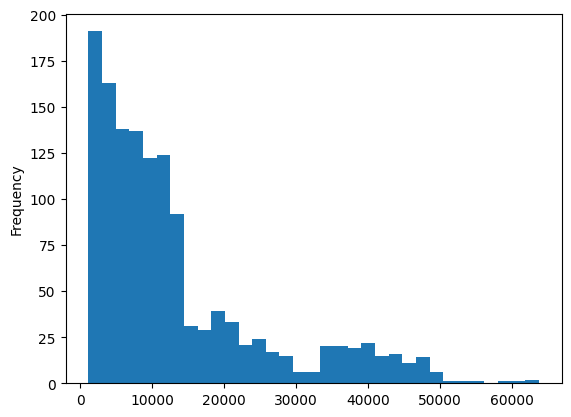

In [68]:
y.plot.hist(bins = 33)

<Axes: >

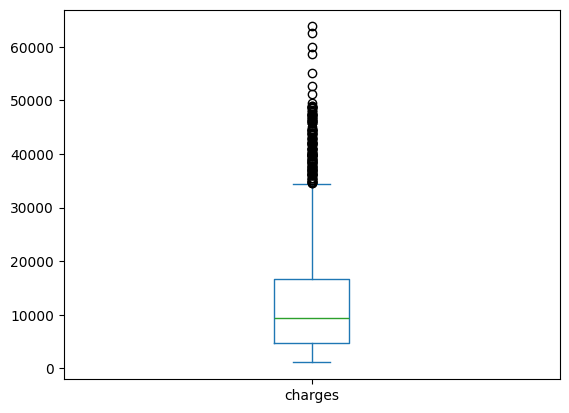

In [69]:
y.plot.box()

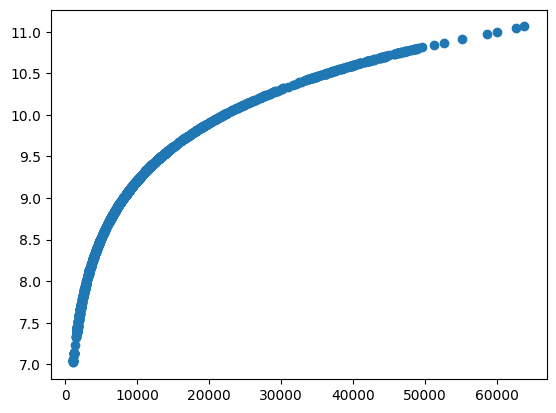

In [71]:
plt.scatter(df.charges, np.log(df.charges))

<Axes: >

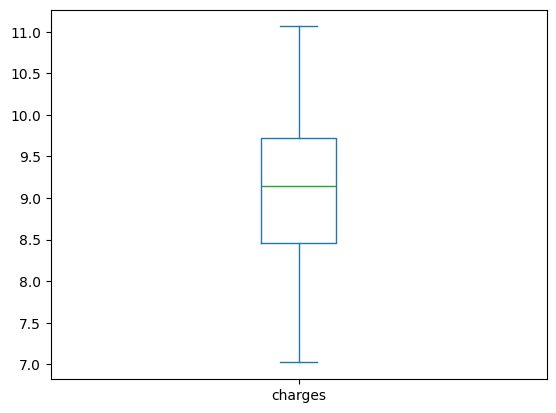

In [72]:
np.log(df.charges).plot.box()

In [73]:
target = 'charges'
X = df.drop(columns=target) # feature matrix
y = np.log(df[target]) # outcome variable/label
X_dummy = pd.get_dummies(X, drop_first=True)
X_train, X_test, y_train, y_test = model_selection.train_test_split(X_dummy, y, test_size = 0.3, 
                                                                   random_state = 978) # random split
scaler = preprocessing.StandardScaler()
X_train_std = scaler.fit_transform(X_train) # find mean and std for each column
X_test_std = scaler.transform(X_test)

X_train_std[:,0]

array([-7.20673328e-02, -7.82120212e-01,  1.34803842e+00,  1.13502256e+00,
       -1.42116780e+00,  1.20602785e+00,  7.79996122e-01,  1.13502256e+00,
        1.77407015e+00,  6.99432430e-02, -8.53125499e-01, -1.35016251e+00,
       -1.35016251e+00, -1.42116780e+00,  1.41904371e+00,  8.51001410e-01,
        1.06401727e+00,  1.13502256e+00,  5.66980258e-01, -1.42116780e+00,
        6.99432430e-02,  4.95974970e-01,  1.13502256e+00,  4.24969682e-01,
       -9.24130787e-01,  4.95974970e-01,  6.99432430e-02, -5.69104348e-01,
        1.06401727e+00,  2.11953819e-01,  5.66980258e-01,  9.93011985e-01,
        1.06401727e+00,  9.22006697e-01,  5.66980258e-01, -1.43072621e-01,
       -1.06204490e-03,  1.41904371e+00,  4.24969682e-01, -1.42116780e+00,
        1.63205958e+00,  2.82959107e-01,  1.40948531e-01, -1.42116780e+00,
       -1.06204490e-03,  5.66980258e-01,  2.11953819e-01, -2.14077909e-01,
        1.70306486e+00, -2.14077909e-01,  1.41904371e+00, -1.27915723e+00,
        3.53964394e-01,  

In [74]:
target = 'charges'
X = df.drop(columns=target) # feature matrix
y = np.log(df[target]) # outcome variable/label
X_dummy = pd.get_dummies(X, drop_first=True)
X_train, X_test, y_train, y_test = model_selection.train_test_split(X_dummy, y, test_size = 0.3, 
                                                                   random_state = 978) # random split
scaler = preprocessing.StandardScaler()
X_train_std = scaler.fit_transform(X_train) # find mean and std for each column
X_test_std = scaler.transform(X_test)

est = linear_model.LinearRegression()
est.fit(X_train_std, y_train) # algortithm finds the parameter values
y_train_pred = est.predict(X_train_std)
y_test_pred = est.predict(X_test_std)

In [76]:
a = pd.DataFrame({'y': y_test, 'y_pred': y_test_pred})
a['error'] = a.y-a.y_pred
a

,y,y_pred,error
1167,8.418362,8.429385,-0.011023
989,9.586850,9.666331,-0.079481
889,9.388079,9.446352,-0.058273
458,9.268742,9.277456,-0.008713
966,10.084449,10.754520,-0.670071
...,...,...,...
984,8.500059,8.625326,-0.125266
978,9.180362,9.473669,-0.293306
842,10.491858,9.822981,0.668876
1251,7.124128,7.722121,-0.597993


In [78]:
np.abs(a['error']).mean() # mean absolution error

np.float64(0.2594939270190672)

In [80]:
np.mean(a['error'] ** 2) # mean squared error

np.float64(0.1582951923304881)

In [81]:
np.mean(a['error'] ** 2) ** 0.5 # root mean squared error

np.float64(0.3978632834661778)

In [82]:
est

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 0.49, 0.08, 0.13,...,-0.03,-0.09,-0.07]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,9.095
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](8,)","[38.24,35.4 ,31.71,...,29.49,26.72,16.82]"


In [83]:
est.coef_

array([ 0.49053869,  0.08332925,  0.13473804, -0.03471389,  0.61995119,
       -0.02788627, -0.08814906, -0.07323298])

In [84]:
X_train.columns

Index(['age', 'bmi', 'children', 'gender_male', 'smoker_yes',
       'region_northwest', 'region_southeast', 'region_southwest'],
      dtype='str')

In [85]:
pd.DataFrame({'feature': X_train.columns, "coefficient": est.coef_})

,feature,coefficient
0,age,0.490539
1,bmi,0.083329
2,children,0.134738
3,gender_male,-0.034714
4,smoker_yes,0.619951
5,region_northwest,-0.027886
6,region_southeast,-0.088149
7,region_southwest,-0.073233


In [86]:
est.intercept_

np.float64(9.094552933892217)

In [ ]:
# y_hat =9.094552933892217 + 0.490539age + 0.083329bmi + ....
# model 

In [87]:
from sklearn import metrics

In [89]:
metrics.mean_squared_error(y_train, y_train_pred), metrics.mean_squared_error(y_test, y_test_pred)

(0.2133258809036372, 0.1582951923304881)

In [91]:
y_train_baseline = y_train.mean()
y_train_baseline

np.float64(9.094552933892217)

In [93]:
sse = ((y_test - y_test_pred) ** 2).sum() # sum of squared error
sst = ((y_test - y_train_baseline)**2).sum() # sum of squared total
r2 = 1 - sse/sst
r2

np.float64(0.7859834532891596)

In [94]:
metrics.r2_score(y_test, y_test_pred)

0.7859294038238243

In [95]:
y_baseline = y_test.mean()
sse = ((y_test - y_test_pred) ** 2).sum() # sum of squared error
sst = ((y_test - y_baseline)**2).sum() # sum of squared total
r2 = 1 - sse/sst
r2

np.float64(0.7859294038238243)

In [96]:
# Hyper parameters: learning rate, tolerance, maximum iterations

In [99]:
target = 'charges'
X = df.drop(columns=target) # feature matrix
y = np.log(df[target]) # outcome variable/label
X_dummy = pd.get_dummies(X, drop_first=True)
X_train, X_test, y_train, y_test = model_selection.train_test_split(X_dummy, y, test_size = 0.3, 
                                                                   random_state = 978) # random split
scaler = preprocessing.StandardScaler()
X_train_std = scaler.fit_transform(X_train) # find mean and std for each column
X_test_std = scaler.transform(X_test)

est = linear_model.LinearRegression()
est.fit(X_train_std, y_train) # algortithm finds the parameter values
y_train_pred = est.predict(X_train_std)
y_test_pred = est.predict(X_test_std)

print("training r2", metrics.r2_score(y_train, y_train_pred))
print("test r2", metrics.r2_score(y_test, y_test_pred))

print("training rmse", metrics.mean_squared_error(y_train, y_train_pred) ** 0.5)
print("test rmse", metrics.mean_squared_error(y_test, y_test_pred) ** 0.5)

training r2 0.76034282274196
test r2 0.7859294038238243
training rmse 0.46187214778944746
test rmse 0.3978632834661778


In [101]:
target = 'charges'
X = df.drop(columns=target) # feature matrix
y = np.log(df[target]) # outcome variable/label
X['high_bmi'] = np.where(X['bmi']>40, 1, 0) # derived feature
X_dummy = pd.get_dummies(X, drop_first=True)
X_train, X_test, y_train, y_test = model_selection.train_test_split(X_dummy, y, test_size = 0.3, 
                                                                   random_state = 978) # random split
scaler = preprocessing.StandardScaler()
X_train_std = scaler.fit_transform(X_train) # find mean and std for each column
X_test_std = scaler.transform(X_test)

est = linear_model.LinearRegression()
est.fit(X_train_std, y_train) # algortithm finds the parameter values
y_train_pred = est.predict(X_train_std)
y_test_pred = est.predict(X_test_std)

print("training r2", metrics.r2_score(y_train, y_train_pred))
print("test r2", metrics.r2_score(y_test, y_test_pred))

print("training rmse", metrics.mean_squared_error(y_train, y_train_pred) ** 0.5)
print("test rmse", metrics.mean_squared_error(y_test, y_test_pred) ** 0.5)

training r2 0.7612443607592945
test r2 0.7875095283862853
training rmse 0.46100259812582756
test rmse 0.3963921847485779


In [109]:
np.random.seed(112)
poly = preprocessing.PolynomialFeatures(degree=2, include_bias=False)
a = np.random.randint(0, 5, (5, 3))
poly.fit_transform(a)

array([[ 4.,  3.,  0., 16., 12.,  0.,  9.,  0.,  0.],
       [ 2.,  1.,  4.,  4.,  2.,  8.,  1.,  4., 16.],
       [ 4.,  0.,  4., 16.,  0., 16.,  0.,  0., 16.],
       [ 1.,  2.,  0.,  1.,  2.,  0.,  4.,  0.,  0.],
       [ 4.,  0.,  0., 16.,  0.,  0.,  0.,  0.,  0.]])

In [108]:
a

array([[4, 3, 0],
       [2, 1, 4],
       [4, 0, 4],
       [1, 2, 0],
       [4, 0, 0]])

In [110]:
target = 'charges'
X = df.drop(columns=target) # feature matrix
y = np.log(df[target]) # outcome variable/label
X['high_bmi'] = np.where(X['bmi']>40, 1, 0) # derived feature
X_dummy = pd.get_dummies(X, drop_first=True)
X_train, X_test, y_train, y_test = model_selection.train_test_split(X_dummy, y, test_size = 0.3, 
                                                                   random_state = 978) # random split


poly = preprocessing.PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.fit_transform(X_test)


scaler = preprocessing.StandardScaler()
X_train_std = scaler.fit_transform(X_train_poly) # find mean and std for each column
X_test_std = scaler.transform(X_test_poly)

est = linear_model.LinearRegression()
est.fit(X_train_std, y_train) # algortithm finds the parameter values
y_train_pred = est.predict(X_train_std)
y_test_pred = est.predict(X_test_std)

print("training r2", metrics.r2_score(y_train, y_train_pred))
print("test r2", metrics.r2_score(y_test, y_test_pred))

print("training rmse", metrics.mean_squared_error(y_train, y_train_pred) ** 0.5)
print("test rmse", metrics.mean_squared_error(y_test, y_test_pred) ** 0.5)

training r2 0.8304053277388531
test r2 0.8753628630619226
training rmse 0.3885372450294815
test rmse 0.3035841442446553
